# Reproducing Figure 6: the two-particle triangle functional

This notebook reproduces the geometry and analytic functional in Figure 6 of Penz and van Leeuwen, *Density-functional theory on graphs* (2021), Eq. (96), p. 18. The domain is

\[
\mathcal P_{3,2}=\{\rho\in[0,1]^3:\rho_1+\rho_2+\rho_3=2\}.
\]

The central disk `C` is a flat region where `F = 3`. To avoid unnecessary computation, the evaluator returns 3 directly for points inside the disk and skips the square roots in the three branches. The plot omits the flat region and shows only its boundary. Outside the disk, it evaluates the three closed-form branches from Eq. (96).

The domain is parameterized as an equilateral triangle with side length 1. The vertical surface shows \(\tilde F(\rho)\). The disk is centered at \( (2/3,2/3,2/3)\), and its boundary in density coordinates satisfies

\[
\sum_{i=1}^3(\rho_i-2/3)^2=1/6.
\]

The three points of tangency on the triangle boundary are the exceptional densities obtained by permuting \( (1,1/2,1/2)\).


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm

# Plot reference: an equilateral triangle with side length 1.
SQRT3 = np.sqrt(3.0)
VERTICES = np.array([
    [0.0, 0.0],              # h1 = 1, rho = (0, 1, 1)
    [1.0, 0.0],              # h2 = 1, rho = (1, 0, 1)
    [0.5, SQRT3 / 2.0],       # h3 = 1, rho = (1, 1, 0)
])
TRIANGLE_CENTER = VERTICES.mean(axis=0)
INCIRCLE_RADIUS = SQRT3 / 6.0


def rho_to_xy(rho):
    """Convert densities (..., 3) to equilateral-triangle coordinates (..., 2)."""
    rho = np.asarray(rho, dtype=float)
    if rho.shape[-1] != 3:
        raise ValueError("The last dimension of rho must have length 3.")
    holes = 1.0 - rho
    return holes @ VERTICES


def xy_to_rho(x, y):
    """Convert equilateral-triangle coordinates to densities (..., 3)."""
    x, y = np.broadcast_arrays(np.asarray(x, dtype=float), np.asarray(y, dtype=float))
    h3 = 2.0 * y / SQRT3
    h2 = x - 0.5 * h3
    h1 = 1.0 - h2 - h3
    holes = np.stack((h1, h2, h3), axis=-1)
    return 1.0 - holes


def _inside_density_domain(rho, tol=1e-10):
    return (
        np.all((rho >= -tol) & (rho <= 1.0 + tol), axis=-1)
        & (np.abs(np.sum(rho, axis=-1) - 2.0) <= tol)
    )


def functional_and_region(rho, tol=1e-12):
    """Vectorized exact F-tilde for one density or a batch shaped (..., 3).

    Points in the central disk return 3 immediately. Outside it, Eq. (96)'s
    three candidate branches are evaluated and the minimum branch is selected.
    Invalid points outside P_(3,2) return NaN and region='outside'.
    """
    rho = np.asarray(rho, dtype=float)
    if rho.shape[-1] != 3:
        raise ValueError("The last dimension of rho must have length 3.")

    original_shape = rho.shape[:-1]
    flat = rho.reshape(-1, 3)
    valid = _inside_density_domain(flat)
    # In ambient density coordinates the incircle has squared radius 1/6.
    dist2 = np.sum((flat - (2.0 / 3.0)) ** 2, axis=1)
    central = valid & (dist2 <= (1.0 / 6.0 + tol))

    values = np.full(len(flat), np.nan, dtype=float)
    region = np.full(len(flat), "outside", dtype=object)
    values[central] = 3.0
    region[central] = "C"

    outer = valid & ~central
    if np.any(outer):
        r = np.clip(flat[outer], 0.0, 1.0)
        r1, r2, r3 = r.T
        # The three square-root factors used in Eq. (96).
        a1 = np.sqrt((1.0 - r1) * (1.0 - r3))
        a2 = np.sqrt((1.0 - r1) * (1.0 - r2))
        a3 = np.sqrt((1.0 - r2) * (1.0 - r3))
        branches = np.stack((
            a1 - a2 - a3,  # S1
            -a1 - a2 + a3, # S2
            -a1 + a2 - a3, # S3
        ), axis=-1)
        active = np.argmin(branches, axis=-1)
        values[outer] = 4.0 + 2.0 * branches[np.arange(np.sum(outer)), active]
        region[outer] = np.array(["S1", "S2", "S3"], dtype=object)[active]

    return values.reshape(original_shape), region.reshape(original_shape)


def functional(rho, tol=1e-12):
    """Fast value-only evaluator for repeated pointwise calculations."""
    rho = np.asarray(rho, dtype=float)
    if rho.shape[-1] != 3:
        raise ValueError("The last dimension of rho must have length 3.")

    original_shape = rho.shape[:-1]
    flat = rho.reshape(-1, 3)
    valid = _inside_density_domain(flat)
    dist2 = np.sum((flat - (2.0 / 3.0)) ** 2, axis=1)
    central = valid & (dist2 <= (1.0 / 6.0 + tol))

    values = np.full(len(flat), np.nan, dtype=float)
    values[central] = 3.0
    outer = valid & ~central
    if np.any(outer):
        r1, r2, r3 = np.clip(flat[outer], 0.0, 1.0).T
        a1 = np.sqrt((1.0 - r1) * (1.0 - r3))
        a2 = np.sqrt((1.0 - r1) * (1.0 - r2))
        a3 = np.sqrt((1.0 - r2) * (1.0 - r3))
        branches = np.stack((
            a1 - a2 - a3,
            -a1 - a2 + a3,
            -a1 + a2 - a3,
        ), axis=-1)
        values[outer] = 4.0 + 2.0 * np.min(branches, axis=-1)

    return values.reshape(original_shape)


## Checks at notable points

The center and the three points of tangency have value 3; the three triangle vertices have value 4. An additional point outside the disk is checked against its analytic branch. These checks do not optimize over phases: use the closed-form expression for repeated pointwise evaluations.


In [5]:
rho_center = np.array([2/3, 2/3, 2/3])
tangent_points = np.array([
    [1.0, 0.5, 0.5],
    [0.5, 1.0, 0.5],
    [0.5, 0.5, 1.0],
])
vertices_rho = np.array([
    [0.0, 1.0, 1.0],
    [1.0, 0.0, 1.0],
    [1.0, 1.0, 0.0],
])

assert np.isclose(functional(rho_center), 3.0)
assert np.allclose(functional(tangent_points), 3.0, atol=1e-10)
assert np.allclose(functional(vertices_rho), 4.0, atol=1e-10)
assert np.allclose(rho_to_xy(xy_to_rho(*TRIANGLE_CENTER)), TRIANGLE_CENTER)

check_rho = np.array([0.133, 0.9335, 0.9335])
check_value, check_region = functional_and_region(check_rho)
print("F(center) =", float(functional(rho_center)))
print("F(tangencies) =", functional(tangent_points))
print("F(vertices) =", functional(vertices_rho))
print(f"F({check_rho}) = {float(check_value):.12f} in {check_region}")


F(center) = 3.0
F(tangencies) = [3. 3. 3.]
F(vertices) = [4. 4. 4.]
F([0.133  0.9335 0.9335]) = 3.172537611356 in S2


## Outer surface and disk boundary

The grid covers the full triangle, but the plot omits the surface over the central disk: its value is known exactly to be 3, and the boundary identifies the region. Grid values are evaluated in a vectorized operation.


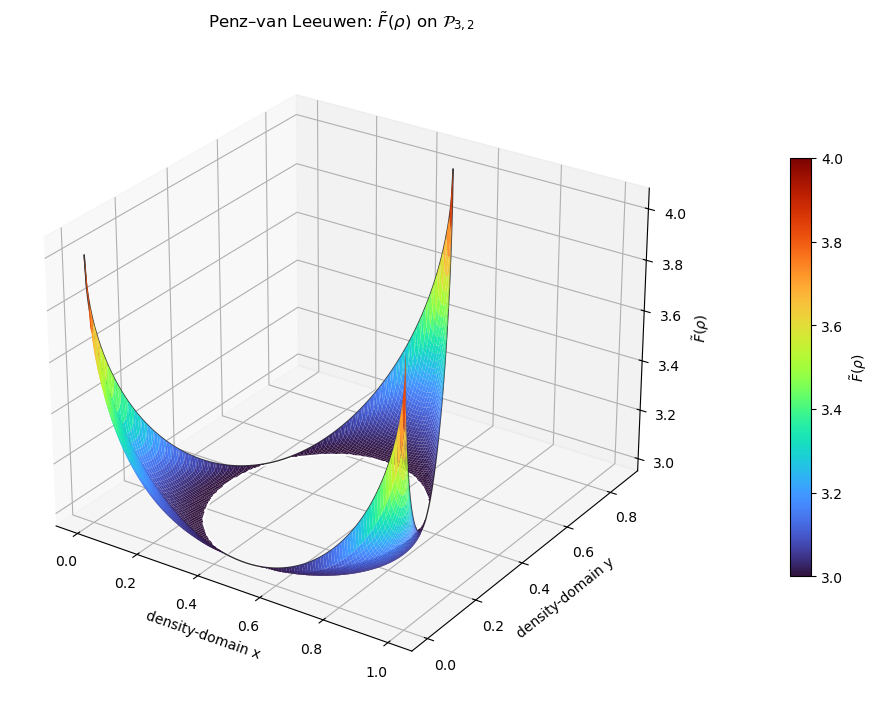

In [7]:
n_grid = 241
x_values = np.linspace(0.0, 1.0, n_grid)
y_values = np.linspace(0.0, SQRT3 / 2.0, n_grid)
X, Y = np.meshgrid(x_values, y_values)
RHO = xy_to_rho(X, Y)

# Mask the rectangular area outside the equilateral triangle.
holes_grid = 1.0 - RHO
in_triangle = np.all(holes_grid >= -1e-10, axis=-1)
Z = functional(RHO)

# Omit the flat region C and draw only its boundary at F = 3.
distance2 = np.sum((RHO - 2.0/3.0)**2, axis=-1)
in_central_disk = distance2 <= (1.0/6.0 + 1e-12)
Z_plot = np.where(in_triangle & ~in_central_disk, Z, np.nan)

fig = plt.figure(figsize=(10, 7.2))
ax = fig.add_subplot(111, projection="3d")
surface = ax.plot_surface(
    X, Y, Z_plot,
    cmap="turbo",
    linewidth=0,
    antialiased=True,
    rcount=180,
    ccount=180,
    vmin=3.0,
    vmax=4.0,
)

# Draw the central circle boundary without computing or plotting the disk interior.
theta = np.linspace(0.0, 2.0*np.pi, 500)
circle_x = TRIANGLE_CENTER[0] + INCIRCLE_RADIUS*np.cos(theta)
circle_y = TRIANGLE_CENTER[1] + INCIRCLE_RADIUS*np.sin(theta)
ax.plot(circle_x, circle_y, np.full_like(theta, 3.0), color="white", linewidth=2.2)

# Draw the domain boundary with heights from the analytic formula.
for i in range(3):
    p0, p1 = VERTICES[i], VERTICES[(i+1) % 3]
    t = np.linspace(0.0, 1.0, 300)
    edge_xy = (1-t[:, None])*p0 + t[:, None]*p1
    edge_rho = xy_to_rho(edge_xy[:, 0], edge_xy[:, 1])
    ax.plot(edge_xy[:, 0], edge_xy[:, 1], functional(edge_rho), color="0.2", linewidth=1.0)

ax.set_xlabel("density-domain x")
ax.set_ylabel("density-domain y")
ax.set_zlabel(r"$\tilde F(\rho)$")
ax.set_title(r"Penz–van Leeuwen: $\tilde F(\rho)$ on $\mathcal{P}_{3,2}$")
ax.set_zlim(2.95, 4.08)
ax.view_init(elev=27, azim=-56)
fig.colorbar(surface, ax=ax, shrink=0.63, pad=0.12, label=r"$\tilde F(\rho)$")
plt.tight_layout()
plt.show()


## 2D domain and boundary

This view shows the density triangle, central disk, and three outer sectors. The circular boundary uses its exact geometric parameterization, so no interior grid is needed.


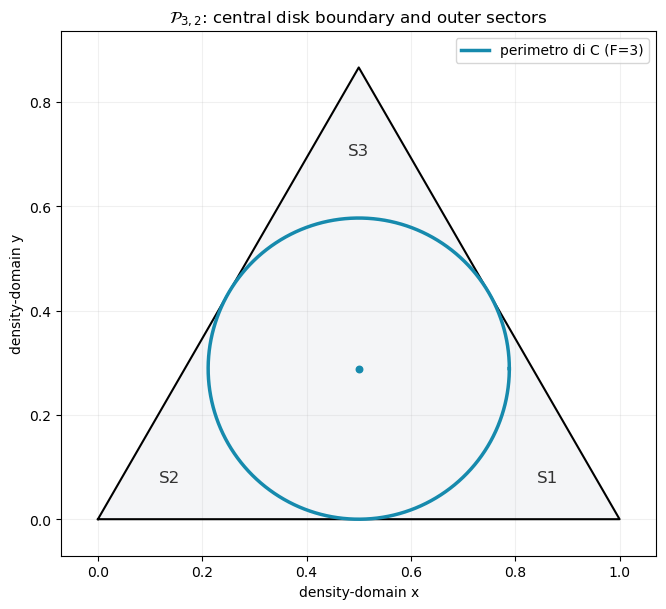

In [9]:
fig2, ax2 = plt.subplots(figsize=(7.0, 6.2))
triangle_closed = np.vstack((VERTICES, VERTICES[0]))
ax2.plot(triangle_closed[:, 0], triangle_closed[:, 1], color="black", linewidth=1.5)
ax2.fill(VERTICES[:, 0], VERTICES[:, 1], color="#f4f5f7", zorder=0)
ax2.plot(circle_x, circle_y, color="#168aad", linewidth=2.5, label="perimetro di C (F=3)")
ax2.scatter(*TRIANGLE_CENTER, color="#168aad", s=22, zorder=3)

# Branch labels in the three outer sectors (Eq. 96).
sector_vertex = {"S2": VERTICES[0], "S1": VERTICES[1], "S3": VERTICES[2]}
for label, vertex in sector_vertex.items():
    direction = vertex - TRIANGLE_CENTER
    label_xy = TRIANGLE_CENTER + 1.45*INCIRCLE_RADIUS*direction/np.linalg.norm(direction)
    ax2.text(*label_xy, label, ha="center", va="center", fontsize=12, color="#333333")

ax2.set_aspect("equal")
ax2.set_xlim(-0.07, 1.07)
ax2.set_ylim(-0.07, SQRT3/2.0 + 0.07)
ax2.set_xlabel("density-domain x")
ax2.set_ylabel("density-domain y")
ax2.set_title(r"$\mathcal{P}_{3,2}$: central disk boundary and outer sectors")
ax2.legend(loc="upper right")
ax2.grid(alpha=0.18)
plt.tight_layout()
plt.show()


## Pointwise evaluation for repeated experiments

`functional(rho_batch)` accepts an array with shape `(n_samples, 3)` and returns all values in one call. Points in the central region receive the exact value 3; the square-root branches are evaluated only for samples outside it. If the samples have already been classified, `functional_and_region` also returns their region labels: `C`, `S1`, `S2`, or `S3`.

For repeated sampling, keep the existing `rho_batch` array and call the function only for new samples. There is no need to optimize over phases for each point.


In [11]:
# Batch interface example (replace with samples from an experiment).
rho_batch = np.array([
    [2/3, 2/3, 2/3],
    [0.133, 0.9335, 0.9335],
    [0.5, 0.5, 1.0],
])
F_batch, region_batch = functional_and_region(rho_batch)
print(np.column_stack((rho_batch, F_batch, region_batch)))


[[0.6666666666666666 0.6666666666666666 0.6666666666666666 3.0 'C']
 [0.133 0.9335 0.9335 3.172537611355864 'S2']
 [0.5 0.5 1.0 3.0 'C']]


## CQITE engine check

Here, the repository's CQITE engine computes the sample values; it does not use the analytic formula. Each point \(\rho\in\mathcal P_{3,2}\) defines the targets for two independent constraints.

\[
C=(Z_1,Z_2),\qquad b_i=\langle Z_i\rangle=1-2\rho_i,\quad i=1,2.
\]

The two-particle condition fixes the third density. For each target, the notebook constructs constraint rotations, seed operators, a commutator basis, and a unitary approximation using the repository pipeline. Each evolution starts from the same phase-parameterized Penz state with phase offsets \( (\pi/2,0)\). The notebook records \(\langle H\rangle\) once the energy stabilizes and the constraints are satisfied, or when it reaches the step limit.

The triangular grid samples a finite set of points in the domain. `N_EDGE=5` gives 21 runs; increasing it creates a denser sample and takes longer. CQITE samples are plotted over the analytic reference. The central region remains omitted, with only its boundary shown.


In [13]:
# Find the CQITE repository beside the notebook or in the current working directory.
import sys
from pathlib import Path

repo_candidates = [
    Path.cwd(),
    Path.cwd().parent,
    Path.cwd() / "work" / "ConstraintQuantumImaginary",
    Path.cwd().parent / "work" / "ConstraintQuantumImaginary",
]
for root in repo_candidates:
    if (root / "cqite").is_dir():
        sys.path.insert(0, str(root))
        REPO_ROOT = root
        break
else:
    raise RuntimeError("Non trovo la cartella cqite; aggiungi la radice del repository a repo_candidates.")

from qiskit.quantum_info import SparsePauliOp, Statevector
from cqite.engine.prepare_state import constraint_rotation, density_from_rotations, support_only
from cqite.ansatz.commutator_basis import CommutatorBasis
from cqite.engine.unitary_approximation import UnitaryApproximation
from cqite.engine.propagation import QITEPropagation
from cqite.simulation.backend import SimulatorBackend

# Triangular Hamiltonian for the Penz–van Leeuwen setup used above.
H = SparsePauliOp(
    ["III", "XXI", "YYI", "IXX", "IYY", "XZX", "YZY"],
    coeffs=[4.0, -0.5, -0.5, -0.5, -0.5, -0.5, -0.5],
)
C = [
    SparsePauliOp("ZII", coeffs=[1.0]),
    SparsePauliOp("IZI", coeffs=[1.0]),
]
Z_ALL = [
    SparsePauliOp("ZII", coeffs=[1.0]),
    SparsePauliOp("IZI", coeffs=[1.0]),
    SparsePauliOp("IIZ", coeffs=[1.0]),
]

# Uniform barycentric grid on the triangle, including its edges and vertices.
N_EDGE = 5
hole_weights = []
for i in range(N_EDGE + 1):
    for j in range(N_EDGE + 1 - i):
        k = N_EDGE - i - j
        hole_weights.append(np.array([i, j, k], dtype=float) / N_EDGE)
hole_weights = np.asarray(hole_weights)
rho_samples = 1.0 - hole_weights
xy_samples = rho_to_xy(rho_samples)
assert np.allclose(rho_samples.sum(axis=1), 2.0)
print(f"Repository: {REPO_ROOT}")
print(f"CQITE experiments: {len(rho_samples)} (N_EDGE={N_EDGE})")


Repository: /Users/dacuomo/Documents/GitHub/ConstraintQuantumImaginary
CQITE experiments: 21 (N_EDGE=5)


In [14]:
# Parameters matched to the repository's Penz–van Leeuwen benchmark.
DT = 1.0e-2
MAX_STEPS = 1000
DEGREE = 2
DEPTH = 4
TROT = 2
PHI_INITIAL = (np.pi / 2.0, 0.0)
ENERGY_STEP_TOL = 1.0e-8
DENSITY_TOL = 2.0e-3
NUMBER_TOL = 2.0e-6
PATIENCE = 20

backend = SimulatorBackend()
_basis_cache = {}
_approx_cache = {}


def penz_initial_state(rho, phases=PHI_INITIAL):
    """Pure N=2 state with density rho, in the basis convention of the benchmark."""
    phi1, phi2 = phases
    data = np.zeros(8, dtype=complex)
    data[6] = np.sqrt(max(0.0, 1.0-rho[2])) * np.exp(1j*phi1)
    data[5] = np.sqrt(max(0.0, 1.0-rho[1])) * np.exp(1j*phi2)
    data[3] = np.sqrt(max(0.0, 1.0-rho[0]))
    return Statevector(data / np.linalg.norm(data))


def cqite_at_density(rho):
    """Run the repository CQITE pipeline for one target density."""
    rho = np.asarray(rho, dtype=float)
    targets_z = 1.0 - 2.0*rho[:2]
    rotations = [
        constraint_rotation(c, float(target))
        for c, target in zip(C, targets_z)
    ]

    rho_seed = density_from_rotations(3, rotations, degree=DEGREE)
    seeds = support_only(rho_seed)
    seed_key = tuple(sorted(seeds.paulis.to_labels()))

    # Reuse objects only when the seed lists match exactly; the pool
    # remains tied to the target in each CQITE run.
    if seed_key not in _basis_cache:
        _basis_cache[seed_key] = CommutatorBasis.from_seed(
            hamiltonian=H, seeds=seeds, depth=DEPTH
        )
        _approx_cache[seed_key] = UnitaryApproximation(
            _basis_cache[seed_key], trot=TROT
        )
    approx = _approx_cache[seed_key]
    prop = QITEPropagation(H, C, backend, approx)

    state = penz_initial_state(rho)
    energies = [float(np.real(state.expectation_value(H)))]
    densities = [np.array([
        (1.0-float(np.real(state.expectation_value(z))))/2.0
        for z in Z_ALL
    ])]
    stable_count = 0
    converged = False

    for step in range(1, MAX_STEPS + 1):
        _, state = prop.step(None, state, DT)
        energy = float(np.real(state.expectation_value(H)))
        density = np.array([
            (1.0-float(np.real(state.expectation_value(z))))/2.0
            for z in Z_ALL
        ])
        energies.append(energy)
        densities.append(density)

        density_residual = np.linalg.norm(density-rho)
        number_residual = abs(np.sum(density)-2.0)
        energy_increment = abs(energies[-1]-energies[-2])
        if (energy_increment <= ENERGY_STEP_TOL
                and density_residual <= DENSITY_TOL
                and number_residual <= NUMBER_TOL):
            stable_count += 1
        else:
            stable_count = 0
        if stable_count >= PATIENCE:
            converged = True
            break

    final_density = densities[-1]
    return {
        "energy": energies[-1],
        "density": final_density,
        "density_residual": float(np.linalg.norm(final_density-rho)),
        "number_residual": float(abs(np.sum(final_density)-2.0)),
        "steps": len(energies)-1,
        "converged": converged,
        "energies": np.asarray(energies),
    }


cqite_results = []
for sample_index, rho in enumerate(rho_samples, start=1):
    cqite_results.append(cqite_at_density(rho))
    if sample_index % 5 == 0 or sample_index == len(rho_samples):
        print(f"Completed {sample_index}/{len(rho_samples)} density targets")

cqite_energy = np.array([r["energy"] for r in cqite_results])
cqite_steps = np.array([r["steps"] for r in cqite_results])
cqite_converged = np.array([r["converged"] for r in cqite_results])
cqite_density_residual = np.array([r["density_residual"] for r in cqite_results])
cqite_number_residual = np.array([r["number_residual"] for r in cqite_results])
cqite_reference = functional(rho_samples)
cqite_error = cqite_energy - cqite_reference

print(f"Converged by stopping rule: {cqite_converged.sum()}/{len(cqite_results)}")
print(f"Median steps: {np.median(cqite_steps):.0f}; max steps: {cqite_steps.max()}")
print(f"Max |E_CQITE - F(rho)|: {np.max(np.abs(cqite_error)):.6e}")
print(f"Max density residual: {np.max(cqite_density_residual):.6e}")
print(f"Max particle-number residual: {np.max(cqite_number_residual):.6e}")
print(f"Distinct cached CQITE pools: {len(_basis_cache)}")


Completed 5/21 density targets
Completed 10/21 density targets
Completed 15/21 density targets
Completed 20/21 density targets
Completed 21/21 density targets
Converged by stopping rule: 21/21
Median steps: 340; max steps: 983
Max |E_CQITE - F(rho)|: 8.826492e-03
Max density residual: 1.307817e-04
Max particle-number residual: 6.644685e-12
Distinct cached CQITE pools: 4


## Comparison: analytic reference and CQITE samples

The analytic surface is shown as a visual reference. Colored points and their heights show the final values measured from the CQITE state for each density target. The central circle is shown by its boundary; CQITE samples inside it remain visible as points.


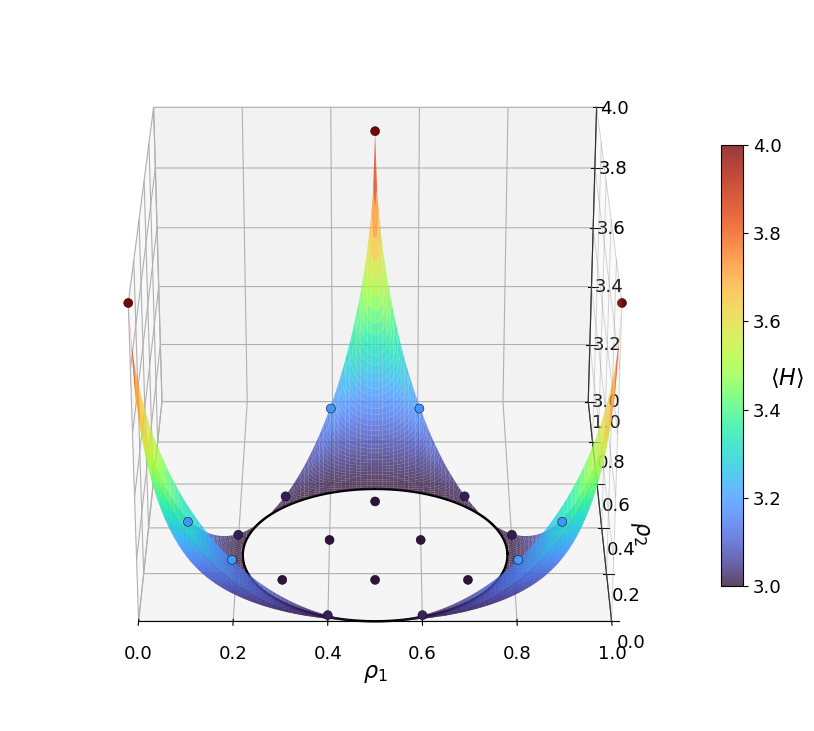

In [33]:
# Analytic reference in the outer sectors; omit the flat disk surface.
Z_reference = np.where(in_triangle & ~in_central_disk, Z, np.nan)

fig_cqite = plt.figure(figsize=(11, 7.8))
ax_cqite = fig_cqite.add_subplot(111, projection="3d")
cmap = plt.get_cmap("turbo")
surface_ref = ax_cqite.plot_surface(
    X, Y, Z_reference,
    cmap=cmap,
    linewidth=0,
    antialiased=True,
    rcount=180,
    ccount=180,
    vmin=3.0,
    vmax=4.0,
    alpha=0.78,
)
ax_cqite.plot(circle_x, circle_y, np.full_like(theta, 3.0),
              color="black", linewidth=1.8, label="perimetro C: F=3")

points_cqite = ax_cqite.scatter(
    xy_samples[:, 0], xy_samples[:, 1], cqite_energy,
    c=cqite_energy,
    cmap=cmap,
    vmin=3.0,
    vmax=4.0,
    s=42,
    edgecolors="black",
    linewidths=0.35,
    depthshade=False,
    label="H",
)

ax_cqite.set_xlabel(r"$\rho_1$")
ax_cqite.set_ylabel(r"$\rho_2$")
#ax_cqite.set_zlabel(r"$\langle H\rangle_{\mathrm{CQITE}}$")
#ax_cqite.set_title("CQITE samples at fixed densities vs. exact Penz–van Leeuwen functional")
ax_cqite.set_xlim(0, 1)
ax_cqite.set_ylim(0, 1)
ax_cqite.set_zlim(3, 4)

# Keep the geometric scale equal on all three axes.
#ax_cqite.set_box_aspect((1, 1, 1))

ax_cqite.view_init(elev=27, azim=-56)
cbar = fig_cqite.colorbar(
    surface_ref, ax=ax_cqite, shrink=0.62, pad=0.0,
    label=r"$\langle H\rangle$"
)

ax_cqite.set_position([0.04, 0.10, 0.78, 0.82])
cbar.ax.set_position([0.85, 0.22, 0.025, 0.56])
ax_cqite.view_init(elev=27, azim=-90)

from mpl_toolkits.mplot3d.art3d import Poly3DCollection

x_right = 1.0
y0, y1 = ax_cqite.get_ylim()
z0, z1 = ax_cqite.get_zlim()

# Use a subtle right wall to keep the surface visible.
wall = Poly3DCollection(
    [[
        (x_right, y0, z0),
        (x_right, y1, z0),
        (x_right, y1, z1),
        (x_right, y0, z1),
    ]],
    facecolor="lightgray",
    edgecolor="none",
    alpha=0.10,
)
ax_cqite.add_collection3d(wall)

# Wall grid.
for y in ax_cqite.get_yticks():
    if y0 <= y <= y1:
        ax_cqite.plot(
            [x_right, x_right], [y, y], [z0, z1],
            color="gray", alpha=0.35, linewidth=0.7
        )

for z in ax_cqite.get_zticks():
    if z0 <= z <= z1:
        ax_cqite.plot(
            [x_right, x_right], [y0, y1], [z, z],
            color="gray", alpha=0.35, linewidth=0.7
        )

cbar.ax.yaxis.label.set_rotation(0)
#cbar.ax.yaxis.labelpad = 10  # adjust the distance from the colorbar
#ax_cqite.legend(loc="upper left")
label_size = 16
tick_size = 13

# 3D figure.
for axis in (ax_cqite.xaxis, ax_cqite.yaxis, ax_cqite.zaxis):
    axis.label.set_size(label_size)
    axis.set_tick_params(labelsize=tick_size)

# Colorbar ticks and labels.
cbar.ax.tick_params(labelsize=tick_size)
cbar.set_label(r"$\langle H\rangle$", fontsize=label_size)


plt.tight_layout()

plt.savefig("cqite_triangle.pdf", bbox_inches="tight", pad_inches=0.02)

plt.show()


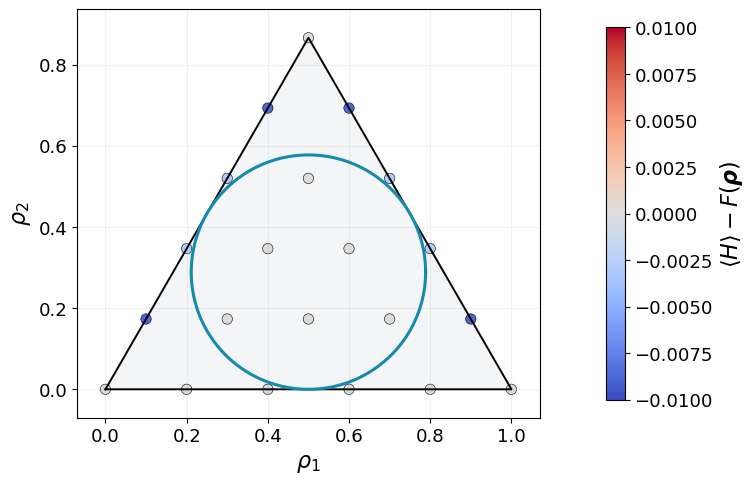

In [35]:
# 2D projection of the samples; color shows the CQITE error relative to the exact value.
fig_err, ax_err = plt.subplots(figsize=(11, 7.8))
ax_err.fill(VERTICES[:, 0], VERTICES[:, 1], color="#f4f5f7", zorder=0)
ax_err.plot(triangle_closed[:, 0], triangle_closed[:, 1], color="black", linewidth=1.4)
ax_err.plot(circle_x, circle_y, color="#168aad", linewidth=2.2, label="perimetro C")
err_scatter = ax_err.scatter(
    xy_samples[:, 0], xy_samples[:, 1],
    c=cqite_error,
    cmap="coolwarm",
    vmin=-max(0.01, np.max(np.abs(cqite_error))),
    vmax=max(0.01, np.max(np.abs(cqite_error))),
    s=56,
    edgecolors="black",
    linewidths=0.4,
)
ax_err.set_aspect("equal")
ax_err.set_xlim(-0.07, 1.07)
ax_err.set_ylim(-0.07, SQRT3/2.0 + 0.07)
ax_err.set_xlabel(r"$\rho_1$")
ax_err.set_ylabel(r"$\rho_2$")
#ax_err.set_title(r"CQITE error at convergence: $E_{\mathrm{CQITE}}-F(\rho)$")
#ax_err.legend(loc="upper right")
cbar_err = fig_err.colorbar(
    err_scatter, ax=ax_err, shrink=0.62, pad=-0.05,
    label=r"$\langle H \rangle -F(\boldsymbol{\rho})$"
)
pos = ax_err.get_position()
scale = 0.68  # reduce the grid; lower the scale factor to make it smaller

ax_err.set_position([
    pos.x0 + (1 - scale) * pos.width / 2,
    pos.y0 + (1 - scale) * pos.height / 2,
    scale * pos.width,
    scale * pos.height,
])
#cbar_err.ax.set_position([0.85, 0.22, 0.025, 0.56])
ax_err.grid(alpha=0.18)
#plt.tight_layout()


#plt.savefig("cqite_triangle_flat.pdf"), bbox_inches="tight", pad_inches=0.02)
from matplotlib.transforms import Bbox

label_size = 16
tick_size = 13

# 2D figure.
for axis in (ax_err.xaxis, ax_err.yaxis):
    axis.label.set_size(label_size)
    axis.set_tick_params(labelsize=tick_size)

# Colorbar ticks and labels.
cbar.ax.tick_params(labelsize=tick_size)
cbar.set_label(r"$\langle H\rangle$", fontsize=label_size)

cbar_err.ax.tick_params(labelsize=tick_size)

fig_err.canvas.draw()
bbox = fig_err.get_tightbbox(fig_err.canvas.get_renderer())

pad_left = 0.05
pad_right = 0.30
pad_y = 0.725

bbox_vertical = Bbox.from_bounds(
    bbox.x0 - pad_left,
    bbox.y0 - pad_y,
    bbox.width + pad_left + pad_right,
    bbox.height + 2 * pad_y,
)


cbar_err.set_label(r"$\langle H\rangle-F(\boldsymbol{\rho})$", fontsize=label_size)

fig_err.savefig("cqite_triangle_flat.pdf",
                bbox_inches=bbox_vertical, pad_inches=0)

plt.show()


### Interpreting the deviations

CQITE enforces the constraints in differential form, so a small residual remains at finite time steps when `DT=0.01`. It is more visible near the domain boundary, where the functional has steep gradients. The second figure and summary statistics report these deviations; the CQITE points are not corrected using the analytic formula. For greater accuracy, reduce `DT` and increase `MAX_STEPS`, at the cost of a longer runtime.


In [19]:
# Sort the table by density to identify samples that did not converge.
order = np.argsort(cqite_error**2)[::-1]
print("worst samples: index, rho, E_CQITE, F_exact, error, steps, converged, density_residual")
for i in order[:min(10, len(order))]:
    print(i, np.round(rho_samples[i], 5),
          f"{cqite_energy[i]:.8f}", f"{cqite_reference[i]:.8f}",
          f"{cqite_error[i]:+.3e}", int(cqite_steps[i]),
          bool(cqite_converged[i]), f"{cqite_density_residual[i]:.3e}")


worst samples: index, rho, E_CQITE, F_exact, error, steps, converged, density_residual
18 [0.2 1.  0.8] 3.19117351 3.20000000 -8.826e-03 340 True 1.306e-04
4 [1.  0.2 0.8] 3.19117351 3.20000000 -8.826e-03 340 True 1.306e-04
6 [0.8 1.  0.2] 3.19118018 3.20000000 -8.820e-03 340 True 1.308e-04
1 [1.  0.8 0.2] 3.19118018 3.20000000 -8.820e-03 340 True 1.308e-04
3 [1.  0.4 0.6] 3.01745484 3.02020410 -2.749e-03 428 True 1.248e-04
15 [0.4 1.  0.6] 3.01745484 3.02020410 -2.749e-03 428 True 1.248e-04
2 [1.  0.6 0.4] 3.01745545 3.02020410 -2.749e-03 428 True 1.249e-04
11 [0.6 1.  0.4] 3.01745545 3.02020410 -2.749e-03 428 True 1.249e-04
16 [0.4 0.8 0.8] 3.00000081 3.00000000 +8.092e-07 911 True 2.539e-05
9 [0.8 0.4 0.8] 3.00000081 3.00000000 +8.092e-07 911 True 2.539e-05
